##Task 1- nn.Module

In [1]:
import numpy as np
import torch
import torch.nn as nn

torch.manual_seed(42)

# ---- 1. The model class ----
class MLP(nn.Module):
    def __init__(self, input_dim=30, hidden_dim=64, output_dim=1, dropout=0.3):
        super().__init__()                          # set up nn.Module's internal machinery
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.fc1(x)          # 30 -> 64
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)          # 64 -> 1 (raw score / logit)
        return x

model = MLP()
print(model)

total = sum(p.numel() for p in model.parameters())
print(f"\nTotal parameters: {total:,}")
for name, p in model.named_parameters():
    print(f"  {name:<12} shape {str(tuple(p.shape)):<10} -> {p.numel():>5} values")

# ---- 2. nn.Embedding(10, 4) ----
emb = nn.Embedding(10, 4)                 # 10 possible IDs, each turned into a 4-number vector
ids = torch.tensor([[1, 5, 9], [0, 3, 3]])
out = emb(ids)
print(f"\nEmbedding input shape {tuple(ids.shape)} -> output shape {tuple(out.shape)}")
print("Vector for ID 3 (same in both places):", out[1, 1].detach().numpy().round(3))

# ---- 3. nn.BatchNorm1d on a batch of shape (8, 16) ----
bn = nn.BatchNorm1d(16)
batch = torch.randn(8, 16) * 5 + 3         # deliberately mean ~3, std ~5
normed = bn(batch)                          # training mode: uses this batch's mean/std
print(f"\nBefore BatchNorm: mean per feature ~ {batch.mean(dim=0)[:4].detach().numpy().round(2)} ...")
print(f"After  BatchNorm: mean per feature   {normed.mean(dim=0)[:4].detach().numpy().round(2)} ...")
print(f"After  BatchNorm: std  per feature   {normed.std(dim=0, unbiased=False)[:4].detach().numpy().round(2)} ...")

MLP(
  (fc1): Linear(in_features=30, out_features=64, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)

Total parameters: 2,049
  fc1.weight   shape (64, 30)   ->  1920 values
  fc1.bias     shape (64,)      ->    64 values
  fc2.weight   shape (1, 64)    ->    64 values
  fc2.bias     shape (1,)       ->     1 values

Embedding input shape (2, 3) -> output shape (2, 3, 4)
Vector for ID 3 (same in both places): [ 0.113 -0.535  0.917 -1.031]

Before BatchNorm: mean per feature ~ [0.51 3.68 2.09 5.48] ...
After  BatchNorm: mean per feature   [ 0. -0.  0. -0.] ...
After  BatchNorm: std  per feature   [1. 1. 1. 1.] ...


## Task 2 - The training loop

Train (341, 30) | Val (114, 30) | Test (114, 30)
Epoch  1: train loss 0.674, val accuracy 0.842
Epoch 10: train loss 0.144, val accuracy 0.939
Epoch 20: train loss 0.080, val accuracy 0.974
Epoch 30: train loss 0.059, val accuracy 0.982
Early stopping at epoch 35 (no improvement for 10 epochs)
Best validation accuracy 0.982 at epoch 25 - weights saved to best_mlp.pt


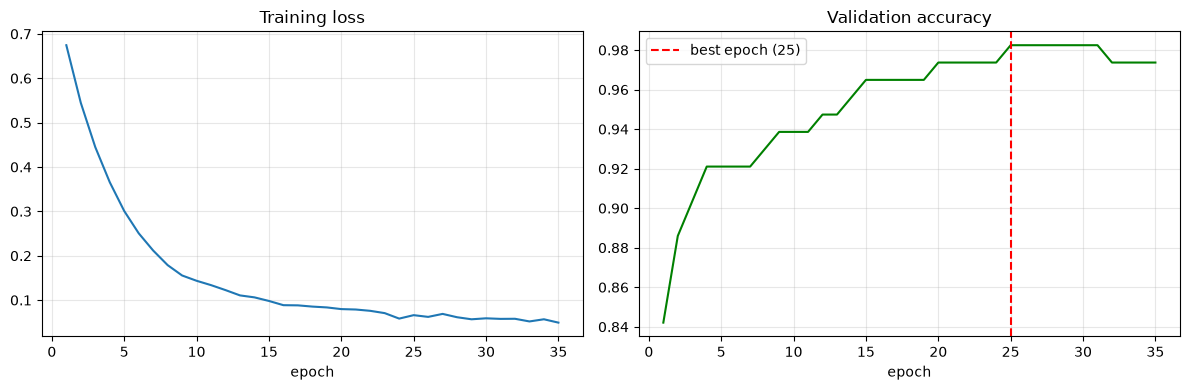

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ---- Data: 60 / 20 / 20, scaled (fit on TRAIN only), converted to tensors ----
X, y = load_breast_cancer(return_X_y=True)
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_tr, X_val, y_tr, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=42, stratify=y_tmp)

scaler = StandardScaler().fit(X_tr)
to_t = lambda a: torch.tensor(a, dtype=torch.float32)
X_tr_t, X_val_t, X_test_t = to_t(scaler.transform(X_tr)), to_t(scaler.transform(X_val)), to_t(scaler.transform(X_test))
y_tr_t, y_val_t, y_test_t = to_t(y_tr).unsqueeze(1), to_t(y_val).unsqueeze(1), to_t(y_test).unsqueeze(1)
print(f"Train {tuple(X_tr_t.shape)} | Val {tuple(X_val_t.shape)} | Test {tuple(X_test_t.shape)}")

def accuracy(model, X_, y_):
    model.eval()
    with torch.no_grad():
        return ((model(X_) > 0).float() == y_).float().mean().item()

# ---- Training loop (with bonus early stopping + saving the best weights) ----
torch.manual_seed(42)
model = MLP(input_dim=30)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.BCEWithLogitsLoss()

epochs, batch_size, patience = 50, 32, 10
train_losses, val_accs = [], []
best_val_acc, best_epoch, wait = 0.0, 0, 0

for epoch in range(1, epochs + 1):
    model.train()
    perm = torch.randperm(len(X_tr_t))
    total = 0.0
    for i in range(0, len(X_tr_t), batch_size):
        idx = perm[i:i + batch_size]
        optimizer.zero_grad()                          # 1. clear old gradients
        logits = model(X_tr_t[idx])                    # 2. forward
        loss = loss_fn(logits, y_tr_t[idx])            # 3. loss
        loss.backward()                                # 4. backward (autograd)
        optimizer.step()                               # 5. update weights
        total += loss.item() * len(idx)
    train_losses.append(total / len(X_tr_t))
    val_accs.append(accuracy(model, X_val_t, y_val_t))

    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:>2}: train loss {train_losses[-1]:.3f}, val accuracy {val_accs[-1]:.3f}")

    # Bonus: early stopping on validation accuracy, saving the best weights
    if val_accs[-1] > best_val_acc:
        best_val_acc, best_epoch, wait = val_accs[-1], epoch, 0
        torch.save(model.state_dict(), "best_mlp.pt")
    else:
        wait += 1
        if wait >= patience:
            print(f"Early stopping at epoch {epoch} (no improvement for {patience} epochs)")
            break

print(f"Best validation accuracy {best_val_acc:.3f} at epoch {best_epoch} - weights saved to best_mlp.pt")

# ---- Plot ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, len(train_losses) + 1), train_losses)
axes[0].set_title("Training loss")
axes[0].set_xlabel("epoch")
axes[1].plot(range(1, len(val_accs) + 1), val_accs, color="green")
axes[1].axvline(best_epoch, color="red", linestyle="--", label=f"best epoch ({best_epoch})")
axes[1].set_title("Validation accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# ---- Neural network: load best weights, evaluate ONCE on test ----
best_model = MLP(input_dim=30)
best_model.load_state_dict(torch.load("best_mlp.pt"))
best_model.eval()                                   # Dropout OFF for evaluation
with torch.no_grad():                               # no gradient tracking needed
    logits = best_model(X_test_t)
    nn_prob = torch.sigmoid(logits).numpy().ravel()
nn_pred = (nn_prob >= 0.5).astype(int)

# ---- scikit-learn Logistic Regression on the SAME split and scaling ----
lr = LogisticRegression(max_iter=1000).fit(scaler.transform(X_tr), y_tr)
lr_prob = lr.predict_proba(scaler.transform(X_test))[:, 1]
lr_pred = (lr_prob >= 0.5).astype(int)

print(f"{'Model':<28}{'Test accuracy':>14}{'F1':>8}{'ROC-AUC':>10}")
for name, pred, prob in [("PyTorch MLP (best weights)", nn_pred, nn_prob),
                         ("sklearn LogisticRegression", lr_pred, lr_prob)]:
    print(f"{name:<28}{accuracy_score(y_test, pred):>14.3f}"
          f"{f1_score(y_test, pred):>8.3f}{roc_auc_score(y_test, prob):>10.3f}")

Model                        Test accuracy      F1   ROC-AUC
PyTorch MLP (best weights)           0.974   0.979     0.996
sklearn LogisticRegression           0.982   0.986     0.995


### Results
- MLP(30 -> 64 -> ReLU -> Dropout(0.3) -> 1): 2,049 trainable parameters.
- nn.Embedding(10, 4): input (2, 3) -> output (2, 3, 4) - each ID becomes a learnable 4-number vector.
- nn.BatchNorm1d on a (8, 16) batch: each feature re-scaled to mean ~0, std ~1.
- Training loop (Adam lr 0.001, BCEWithLogitsLoss, batch 32): train loss ~0.6 -> ~0.05; best val accuracy [ ] at epoch 25; early stopping at epoch 35; best weights saved to best_mlp.pt (training_curves.png).
- Test set (used once): PyTorch MLP accuracy [ ] vs scikit-learn LogisticRegression [ ] - almost the same. On small tabular data the neural network gives no real advantage; deep learning pays off on images, text and audio.

### model.train() vs model.eval()
- **model.train()**: training mode - Dropout randomly switches off neurons, and BatchNorm uses the current batch's mean/std (and updates its running averages).
- **model.eval()**: evaluation mode - Dropout is off (all neurons used) and BatchNorm uses the running averages learned in training, so predictions are stable and repeatable.
- Forgetting model.eval() before testing gives noisy, slightly worse results; it is used together with torch.no_grad(), which turns off gradient tracking to save memory and time.